In [19]:
import os
import sys

project_root = "Incremental-Learning-MycroftMinds"
cwd = os.path.abspath(os.getcwd())
while True:
    if os.path.basename(cwd) == project_root:
        if cwd not in sys.path:
            sys.path.insert(0, cwd)
        break
    parent = os.path.dirname(cwd)
    if parent == cwd:
        raise FileNotFoundError(f"Project root '{project_root}' not found in any parent directory.")
    cwd = parent

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import tqdm
import copy

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error

from src.trees.fastodt import FastODT

from src.ensemble_methods.elasticGBDT import ElasticGBDT
from src.ensemble_methods.LearnNSE import LearnNSE  

In [21]:
import numpy as np

# --- PARAMETERS ---
n_batches               = 30
n_samples_per_batch     = 5
noise_std               = 0.7
concept_drift_strength  = 10.2   # 0=no drift; 1=exactly to end; >1=overshoot

# Linear models for start & end concepts
START_W, END_W = np.array([1.0, 1.0]), np.array([2.0, -1.0])
START_B, END_B = 0.0, 0.5

# --- 1) Drift generators with unbounded strength ---

def generate_sudden_drift(t, n_batches, n_samples, noise_std, strength):
    """
    Sudden step at midpoint: if t <= mid   ⇒ alpha=0,
                          else            ⇒ alpha=1,
    then w = START_W + strength*(END_W-START_W).
    """
    X = np.random.rand(n_samples, 2)
    mid = n_batches // 2
    alpha = 1.0 if t > mid else 0.0
    w = START_W + strength * alpha * (END_W - START_W)
    b = START_B + strength * alpha * (END_B - START_B)
    y = X.dot(w) + b + np.random.randn(n_samples) * noise_std
    return X, y

def generate_incremental_drift(t, n_batches, n_samples, noise_std, strength):
    """
    Linear ramp: base_frac = t/(n_batches-1),
    then alpha = base_frac * strength (no clipping).
    """
    X = np.random.rand(n_samples, 2)
    base_frac = t / (n_batches - 1)
    alpha = base_frac * strength
    w = START_W + alpha * (END_W - START_W)
    b = START_B + alpha * (END_B - START_B)
    y = X.dot(w) + b + np.random.randn(n_samples) * noise_std
    return X, y

def generate_gradual_drift(t, n_batches, n_samples, noise_std, strength):
    """
    Smooth (cosine) schedule: 
      eased = 0.5*(1 - cos(pi * t/(n_batches-1)))
    then alpha = eased * strength (no clipping).
    """
    X = np.random.rand(n_samples, 2)
    eased = 0.5 * (1 - np.cos(np.pi * t / (n_batches - 1)))
    alpha = eased * strength
    w = START_W + alpha * (END_W - START_W)
    b = START_B + alpha * (END_B - START_B)
    y = X.dot(w) + b + np.random.randn(n_samples) * noise_std
    return X, y

# --- 2) Drift schedule & selector ---

# Phases across 30 batches (indices 0–29)
schedule = [
    (generate_incremental_drift,  0,  10),
    (generate_sudden_drift,      11,  19),
    (generate_gradual_drift,     20,  29),
]

def drift_fn(batch_idx, n_samples):
    for fn, start, end in schedule:
        if start <= batch_idx <= end:
            return fn(batch_idx, n_batches, n_samples, noise_std, concept_drift_strength)
    # Fallback (shouldn't happen)
    return generate_incremental_drift(batch_idx, n_batches, n_samples, noise_std, concept_drift_strength)


Loaded 20 trees from the pretrained model. m_threshold=0
Loaded 20 trees from the pretrained model. m_threshold=0


 14%|█▍        | 4/29 [00:00<00:00, 32.94it/s]

Wrong option in option: HF, available options: ['hf', 'cb']. Falling back to default: 'hf'.
Wrong option in option: HF, available options: ['hf', 'cb']. Falling back to default: 'hf'.
[Index-Based] Best tree index = 4, Error = 0.4931
[Index-Based] Pruned 15 trees. Now 5 remain.
[Weighted Ratio] History length 1 < 4; no tree deletion.
Wrong option in option: HF, available options: ['hf', 'cb']. Falling back to default: 'hf'.
Wrong option in option: HF, available options: ['hf', 'cb']. Falling back to default: 'hf'.
[Index-Based] Best tree index = 15, Error = 0.5125
[Index-Based] Pruned 4 trees. Now 16 remain.
[Weighted Ratio] History length 2 < 4; no tree deletion.
Wrong option in option: HF, available options: ['hf', 'cb']. Falling back to default: 'hf'.
Wrong option in option: HF, available options: ['hf', 'cb']. Falling back to default: 'hf'.
[Index-Based] Best tree index = 0, Error = 0.4306
[Index-Based] Pruned 19 trees. Now 1 remain.
[Weighted Ratio] History length 3 < 4; no tree d

 28%|██▊       | 8/29 [00:00<00:00, 23.44it/s]

Wrong option in option: HF, available options: ['hf', 'cb']. Falling back to default: 'hf'.
Wrong option in option: HF, available options: ['hf', 'cb']. Falling back to default: 'hf'.
[Index-Based] Best tree index = 19, Error = 0.6507
[Index-Based] Pruned 0 trees. Now 20 remain.
[Weighted Ratio] e(t-4)=1.988, e(t-3)=3.778, e(t-2)=0.124, e(t-1)=4.117, e(t)=0.686
[Weighted Ratio] ratio1=1.900, ratio2=0.033, ratio3=0.167, weighted_ratio=0.316, removal_count=0
Wrong option in option: HF, available options: ['hf', 'cb']. Falling back to default: 'hf'.
Wrong option in option: HF, available options: ['hf', 'cb']. Falling back to default: 'hf'.
[Index-Based] Best tree index = 13, Error = 5.1169
[Index-Based] Pruned 6 trees. Now 14 remain.
[Weighted Ratio] e(t-4)=3.778, e(t-3)=0.124, e(t-2)=4.117, e(t-1)=0.686, e(t)=6.519
[Weighted Ratio] ratio1=0.033, ratio2=33.210, ratio3=9.508, weighted_ratio=16.622, removal_count=20
Wrong option in option: HF, available options: ['hf', 'cb']. Falling back t

 38%|███▊      | 11/29 [00:00<00:00, 21.93it/s]

... (5 outputs left out)

 86%|████████▌ | 25/29 [00:01<00:00, 19.70it/s]

Wrong option in option: HF, available options: ['hf', 'cb']. Falling back to default: 'hf'.
Wrong option in option: HF, available options: ['hf', 'cb']. Falling back to default: 'hf'.
[Index-Based] Best tree index = 8, Error = 6.6946
[Index-Based] Pruned 11 trees. Now 9 remain.
[Weighted Ratio] e(t-4)=24.572, e(t-3)=10.679, e(t-2)=3.870, e(t-1)=4.282, e(t)=8.060
[Weighted Ratio] ratio1=0.435, ratio2=0.362, ratio3=1.882, weighted_ratio=1.470, removal_count=2
Wrong option in option: HF, available options: ['hf', 'cb']. Falling back to default: 'hf'.
Wrong option in option: HF, available options: ['hf', 'cb']. Falling back to default: 'hf'.
[Index-Based] Best tree index = 11, Error = 5.6235
[Index-Based] Pruned 8 trees. Now 12 remain.
[Weighted Ratio] e(t-4)=10.679, e(t-3)=3.870, e(t-2)=4.282, e(t-1)=8.060, e(t)=5.536
[Weighted Ratio] ratio1=0.362, ratio2=1.107, ratio3=0.687, weighted_ratio=0.849, removal_count=1
Wrong option in option: HF, available options: ['hf', 'cb']. Falling back to

100%|██████████| 29/29 [00:01<00:00, 20.14it/s]

Wrong option in option: HF, available options: ['hf', 'cb']. Falling back to default: 'hf'.
Wrong option in option: HF, available options: ['hf', 'cb']. Falling back to default: 'hf'.
[Index-Based] Best tree index = 19, Error = 7.2476
[Index-Based] Pruned 0 trees. Now 20 remain.
[Weighted Ratio] e(t-4)=8.060, e(t-3)=5.536, e(t-2)=3.848, e(t-1)=6.336, e(t)=11.620
[Weighted Ratio] ratio1=0.687, ratio2=0.695, ratio3=1.834, weighted_ratio=1.561, removal_count=2
Wrong option in option: HF, available options: ['hf', 'cb']. Falling back to default: 'hf'.
Wrong option in option: HF, available options: ['hf', 'cb']. Falling back to default: 'hf'.
[Index-Based] Best tree index = 18, Error = 17.6555
[Index-Based] Pruned 1 trees. Now 19 remain.
[Weighted Ratio] e(t-4)=5.536, e(t-3)=3.848, e(t-2)=6.336, e(t-1)=11.620, e(t)=8.372
[Weighted Ratio] ratio1=0.695, ratio2=1.647, ratio3=0.720, weighted_ratio=1.068, removal_count=1
Wrong option in option: HF, available options: ['hf', 'cb']. Falling back t

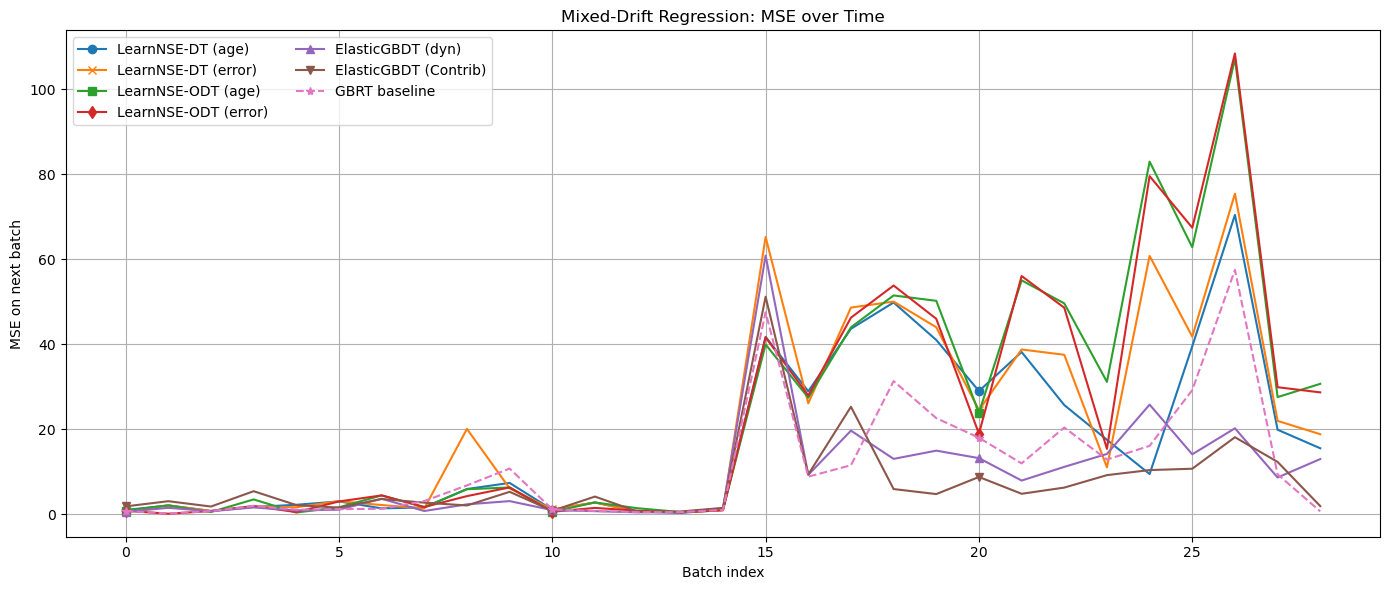

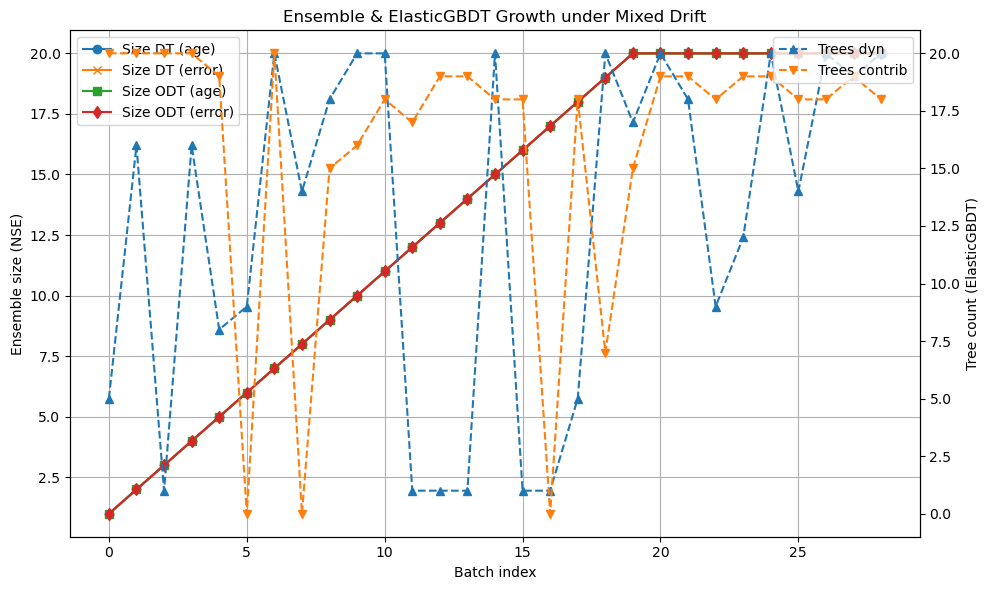


Mean MSE:
LearnNSE-DT (age)    : 17.3407
LearnNSE-DT (error)  : 21.0262
LearnNSE-ODT (age)   : 24.7309
LearnNSE-ODT (error) : 24.0105
ElasticGBDT (dyn)    : 9.1748
ElasticGBDT (contrib)   : 7.4522
GBRT baseline        : 11.3608


In [22]:
def get_tree_count(m):
    # GradientBoostingRegressor: .estimators_ is an array of shape (n_estimators, 1)
    if hasattr(m, "estimators_"):
        return m.n_estimators  # m.estimators_.shape[0]
    # FastODT or custom: maybe stored in .trees
    return len(getattr(m, "trees", []))

# --- 2) Instantiate LearnNSE ensembles ---
# DecisionTree‐based
nse_age_dt = LearnNSE(
    base_classifier=DecisionTreeRegressor,
    ensemble_size=ensemble_size,
    pruning_type='age',
    alpha=0.5,
    beta=10.0,
    regression_task_error_metric=mean_squared_error
)
nse_error_dt = LearnNSE(
    base_classifier=DecisionTreeRegressor,
    ensemble_size=ensemble_size,
    pruning_type='error',
    alpha=0.5,
    beta=10.0,
    regression_task_error_metric=mean_squared_error
)

# FastODT‐based
nse_age_odt = LearnNSE(
    base_classifier=FastODT,
    ensemble_size=ensemble_size,
    pruning_type='age',
    alpha=0.5,
    beta=10.0,
    regression_task_error_metric=mean_squared_error
)
nse_error_odt = LearnNSE(
    base_classifier=FastODT,
    ensemble_size=ensemble_size,
    pruning_type='error',
    alpha=0.5,
    beta=10.0,
    regression_task_error_metric=mean_squared_error
)

# static GBRT baseline
gb_reg = GradientBoostingRegressor(n_estimators=ensemble_size, random_state=0)



# --- 4) Prepare tracking lists ---

# MSE lists
mse_age_dt, mse_error_dt = [], []
mse_age_odt, mse_error_odt = [], []
mse_dyn, mse_stat = [], []
mse_gb = []

# size / tree‐count lists
size_age_dt, size_error_dt = [], []
size_age_odt, size_error_odt = [], []
trees_dyn, trees_stat = [], []

# --- 5) Initial fit of GBRT and ElasticGBDT minitialization ---

X0, y0 = drift_fn(0, n_samples_per_batch)
gb_reg.fit(X0, y0)
# For ElasticGBDT: you’ve already passed y_train; models are initialized from the pretrained GBRT.

# --- 3) Instantiate ElasticGBDT variants ---

# Dynamic index-based update
index_dyn = ElasticGBDT(
    pretrained_model=copy.deepcopy(gb_reg),
    y_train=drift_fn(0, n_samples_per_batch)[1],
    m_threshold=0,
    error_metric=mean_squared_error
)
index_dyn.name = 'dyn'

# Static contribution-weighted update
index_contrib = ElasticGBDT(
    pretrained_model=copy.deepcopy(gb_reg),
    y_train=drift_fn(0, n_samples_per_batch)[1],
    m_threshold=0,
    error_metric=mean_squared_error
)
index_contrib.name = 'contrib'

# --- 6) Online loop ---

for t in tqdm.tqdm(range(n_batches - 1)):
    X_train, y_train = drift_fn(t, n_samples_per_batch)

    # 6a) Update LearnNSE and GBRT
    for model in (nse_age_dt, nse_error_dt, nse_age_odt, nse_error_odt):
        model.fit(X_train, y_train)
    gb_reg.fit(X_train, y_train)

    # 6b) Update ElasticGBDT–dynamic
    bef = get_tree_count(index_dyn)
    index_dyn.update_index_based(X_train, y_train)
    aft = get_tree_count(index_dyn)
    # auto‐build new trees to reach bef if needed
    if aft < bef:
        index_dyn.build_incremental_trees(
            X_train, y_train - index_dyn.predict(X_train), bef - aft
        )
    trees_dyn.append(aft)

    # 6c) Update ElasticGBDT–contribution
    bef_s = get_tree_count(index_contrib)
    index_contrib.update_contribution_weighted_ratio(X_train, y_train,
                                                alpha_multiplier=0.7, beta_multiplier=0.3,
                                                gamma_multiplier=0.1, fixed_multiplier= 1.2)
    aft_s = get_tree_count(index_contrib)
    if aft_s < bef_s:
        index_contrib.build_incremental_trees(
            X_train, y_train - index_contrib.predict(X_train), bef_s - aft_s
        )
    trees_stat.append(aft_s)

    # 6d) Record sizes / tree counts immediately after updates
    size_age_dt.append(len(nse_age_dt.models))
    size_error_dt.append(len(nse_error_dt.models))
    size_age_odt.append(len(nse_age_odt.models))
    size_error_odt.append(len(nse_error_odt.models))
    # 6e) Evaluate on next batch
    X_test, y_test = drift_fn(t + 1, n_samples_per_batch)
    mse_age_dt.append(  mean_squared_error(y_test, nse_age_dt.predict(X_test))   )
    mse_error_dt.append(mean_squared_error(y_test, nse_error_dt.predict(X_test)) )
    mse_age_odt.append(  mean_squared_error(y_test, nse_age_odt.predict(X_test))   )
    mse_error_odt.append(mean_squared_error(y_test, nse_error_odt.predict(X_test)) )
    mse_dyn.append(      mean_squared_error(y_test, index_dyn.predict(X_test))     )
    mse_stat.append(     mean_squared_error(y_test, index_contrib.predict(X_test))    )
    mse_gb.append(       mean_squared_error(y_test, gb_reg.predict(X_test))        )

# --- 7) Plotting MSE curves ---

plt.figure(figsize=(14, 6))
plt.plot(mse_age_dt,    label='LearnNSE-DT (age)',    marker='o', markevery=10)
plt.plot(mse_error_dt,  label='LearnNSE-DT (error)',  marker='x', markevery=10)
plt.plot(mse_age_odt,   label='LearnNSE-ODT (age)',   marker='s', markevery=10)
plt.plot(mse_error_odt, label='LearnNSE-ODT (error)', marker='d', markevery=10)
plt.plot(mse_dyn,       label='ElasticGBDT (dyn)',    marker='^', markevery=10)
plt.plot(mse_stat,      label='ElasticGBDT (Contrib)',   marker='v', markevery=10)
plt.plot(mse_gb,        '--',                       label='GBRT baseline',      marker='*', markevery=10)
plt.xlabel('Batch index')
plt.ylabel('MSE on next batch')
plt.title('Mixed-Drift Regression: MSE over Time')
plt.legend(ncol=2)
plt.grid(True)
plt.tight_layout()
plt.show()

# --- 8) Plotting ensemble/tree-count growth ---

fig, ax1 = plt.subplots(figsize=(10, 6))
# LearnNSE sizes
ax1.plot(size_age_dt,    label='Size DT (age)',    marker='o')
ax1.plot(size_error_dt,  label='Size DT (error)',  marker='x')
ax1.plot(size_age_odt,   label='Size ODT (age)',   marker='s')
ax1.plot(size_error_odt, label='Size ODT (error)', marker='d')
ax1.set_xlabel('Batch index')
ax1.set_ylabel('Ensemble size (NSE)')
ax1.legend(loc='upper left')
ax1.grid(True)

# ElasticGBDT tree counts on secondary y-axis
ax2 = ax1.twinx()
ax2.plot(trees_dyn,  '--', label='Trees dyn',  marker='^')
ax2.plot(trees_stat, '--', label='Trees contrib', marker='v')
ax2.set_ylabel('Tree count (ElasticGBDT)')
ax2.legend(loc='upper right')

plt.title('Ensemble & ElasticGBDT Growth under Mixed Drift')
plt.tight_layout()
plt.show()

# --- 9) Summary stats ---

print("\nMean MSE:")
print(f"LearnNSE-DT (age)    : {np.mean(mse_age_dt):.4f}")
print(f"LearnNSE-DT (error)  : {np.mean(mse_error_dt):.4f}")
print(f"LearnNSE-ODT (age)   : {np.mean(mse_age_odt):.4f}")
print(f"LearnNSE-ODT (error) : {np.mean(mse_error_odt):.4f}")
print(f"ElasticGBDT (dyn)    : {np.mean(mse_dyn):.4f}")
print(f"ElasticGBDT (contrib)   : {np.mean(mse_stat):.4f}")
print(f"GBRT baseline        : {np.mean(mse_gb):.4f}")
